# NIST TN 1822 — Verif.2.4: Assigned agent demographics

100 agents in a 100 m x 100 m room with desired speeds sampled from Gaussian(mu=1.2, sigma=0.2). No exit; the verification target is the distribution of assigned speeds, not evacuation behaviour.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 11:40 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles

## Load and inspect the scenario

In [5]:
SCENARIO_ZIP = Path("scenario_files") / "Nist-2-4-demographics.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
params = scenario.distributions['jps-distributions_0']['parameters']
print(f'v0 = {params["v0"]} m/s, v0_distribution = {params["v0_distribution"]}, '
      f'v0_std = {params.get("v0_std", "n/a")}, n = {params["number"]}')

v0 = 1.2 m/s, v0_distribution = gaussian, v0_std = 0.2, n = 100


## Scenario figure

100 agents are placed in a large room without an exit.

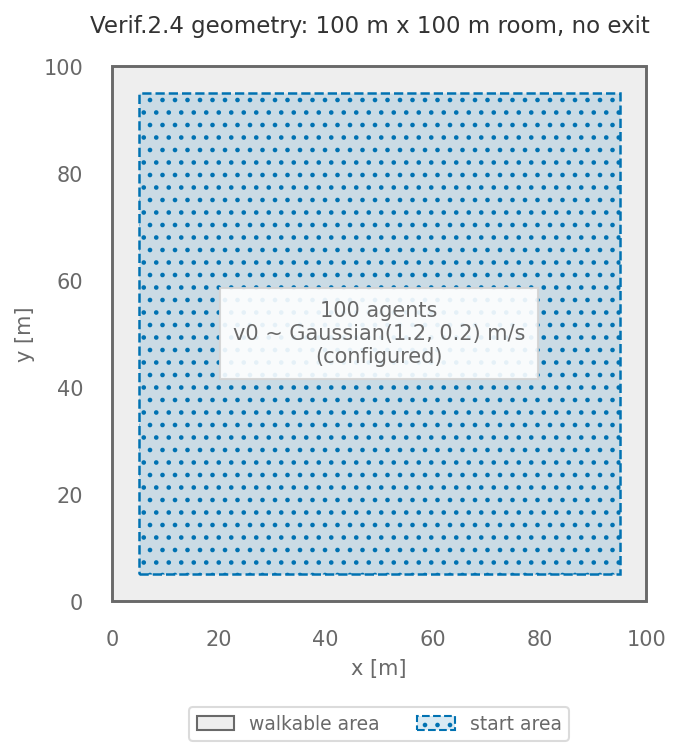

In [6]:
# Scenario geometry from the loaded ZIP.
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(5.2, 5.0))
    handles = vv_draw_scenario(ax, scenario)
    start = scenario.distributions["jps-distributions_0"]
    c = Polygon(start["coordinates"]).centroid
    ax.text(c.x, c.y, f"{params['number']} agents\n"
            f"v0 ~ Gaussian({params['v0']}, {params['v0_std']}) m/s\n(configured)",
            ha="center", va="center", color="dimgrey",
            bbox={"facecolor": "white", "edgecolor": "lightgrey", "alpha": 0.9, "pad": 6})
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    ax.set_title(f"Verif.2.4 geometry: {maxx - minx:g} m x {maxy - miny:g} m room, "
                 + ("no exit" if not scenario.exits else f"{len(scenario.exits)} exits"), loc="left")
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
    plt.show()

## Reference Gaussian (mu=1.2, sigma=0.2)

Without an exit the agents do not move, so we cannot recover observed speeds from trajectories. Instead we show the analytic distribution the loader is configured to sample from.

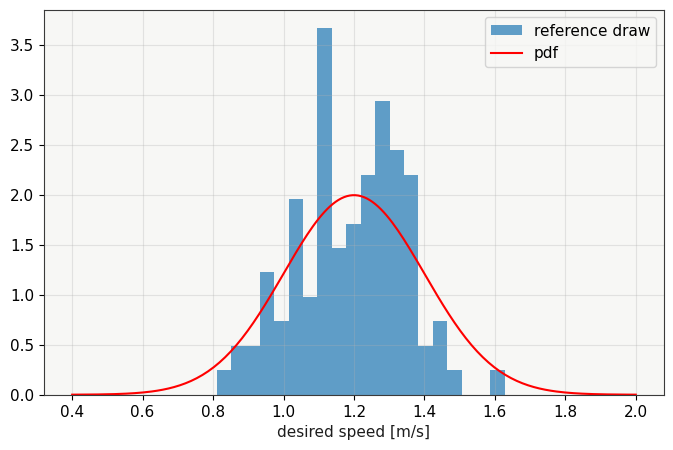

In [7]:
rng = np.random.default_rng(seed=42)
reference = rng.normal(params['v0'], params['v0_std'], int(params['number']))
fig, ax = plt.subplots()
ax.hist(reference, bins=20, density=True, alpha=0.7, label='reference draw')
xs = np.linspace(0.4, 2.0, 200)
ax.plot(xs, (1 / (params['v0_std'] * np.sqrt(2 * np.pi)))
        * np.exp(-0.5 * ((xs - params['v0']) / params['v0_std']) ** 2), 'r-', label='pdf')
ax.set_xlabel('desired speed [m/s]')
ax.legend()
plt.show()

## Acceptance

In [8]:
assert params['v0_distribution'] == 'gaussian'
assert abs(params['v0'] - 1.2) < 1e-6
assert abs(params['v0_std'] - 0.2) < 1e-6
print('scenario configured for Gaussian(1.2, 0.2)')

scenario configured for Gaussian(1.2, 0.2)


## Result figure

This test checks the configuration only (distribution type, mean, standard deviation, count). Agents do not move without an exit, so there are no simulated speeds. The histogram is a reference draw from the configured Gaussian.

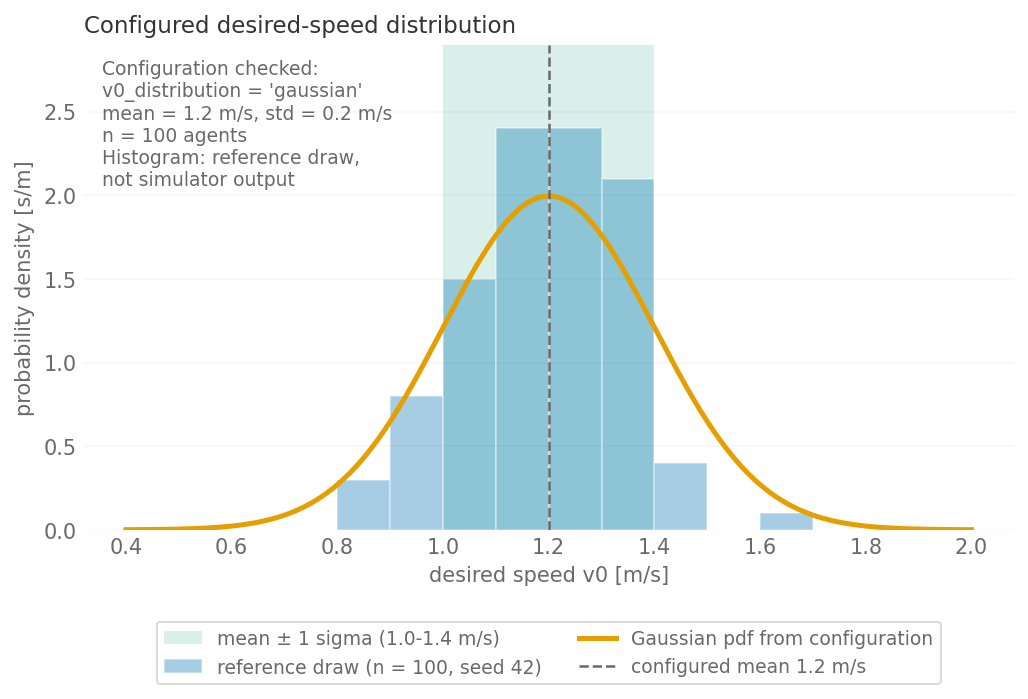

In [9]:
# Configured target distribution against a reference draw of the same size.
mu, sd, n = params["v0"], params["v0_std"], int(params["number"])
xs = np.linspace(mu - 4 * sd, mu + 4 * sd, 300)
pdf = np.exp(-0.5 * ((xs - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi))
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.axvspan(mu - sd, mu + sd, color=VV_GREEN, alpha=0.15, lw=0, label=f"mean ± 1 sigma ({mu - sd:.1f}-{mu + sd:.1f} m/s)")
    ax.hist(reference, bins=np.arange(0.4, 2.01, 0.1), density=True, color=VV_BLUE, alpha=0.35,
            edgecolor="white", label=f"reference draw (n = {n}, seed 42)")
    ax.plot(xs, pdf, color=VV_ORANGE, lw=2.4, label="Gaussian pdf from configuration")
    ax.axvline(mu, color="dimgrey", ls="--", lw=1.2, label=f"configured mean {mu:g} m/s")
    ax.set_xlabel("desired speed v0 [m/s]")
    ax.set_ylabel("probability density [s/m]")
    ax.set_title("Configured desired-speed distribution", loc="left")
    ax.text(0.02, 0.97, f"Configuration checked:\nv0_distribution = '{params['v0_distribution']}'\n"
            f"mean = {mu:g} m/s, std = {sd:g} m/s\nn = {n} agents\n"
            "Histogram: reference draw,\nnot simulator output",
            transform=ax.transAxes, ha="left", va="top", color="dimgrey", fontsize=9)
    ax.set_ylim(0, 2.9)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
    ax.grid(axis="x", visible=False)
    plt.show()